In [1]:
import numpy as np
from ChernNumber import chern_number_two_lowest
from matplotlib import pyplot as plt

In [ ]:
m_values = np.linspace(-5, -2, 100)
Delta_values = np.linspace(0, 0.25, 100)
c_coll = np.zeros((len(m_values), len(Delta_values)))

for i, m in enumerate(m_values):
    for j, Delta in enumerate(Delta_values):
        print(f"Computing Chern number for m={m:.4f}, Delta={Delta:.4f}")
        c = chern_number_two_lowest(m=m, t=1.0, Delta=Delta, Nk=100)
        c_coll[i, j] = c

Computing Chern number for m=-5.0000, Delta=0.0000
Computing Chern number for m=-5.0000, Delta=0.0025
Computing Chern number for m=-5.0000, Delta=0.0051


In [29]:
np.savetxt("ChernNumber_sweep.csv", c_coll, delimiter = ",")

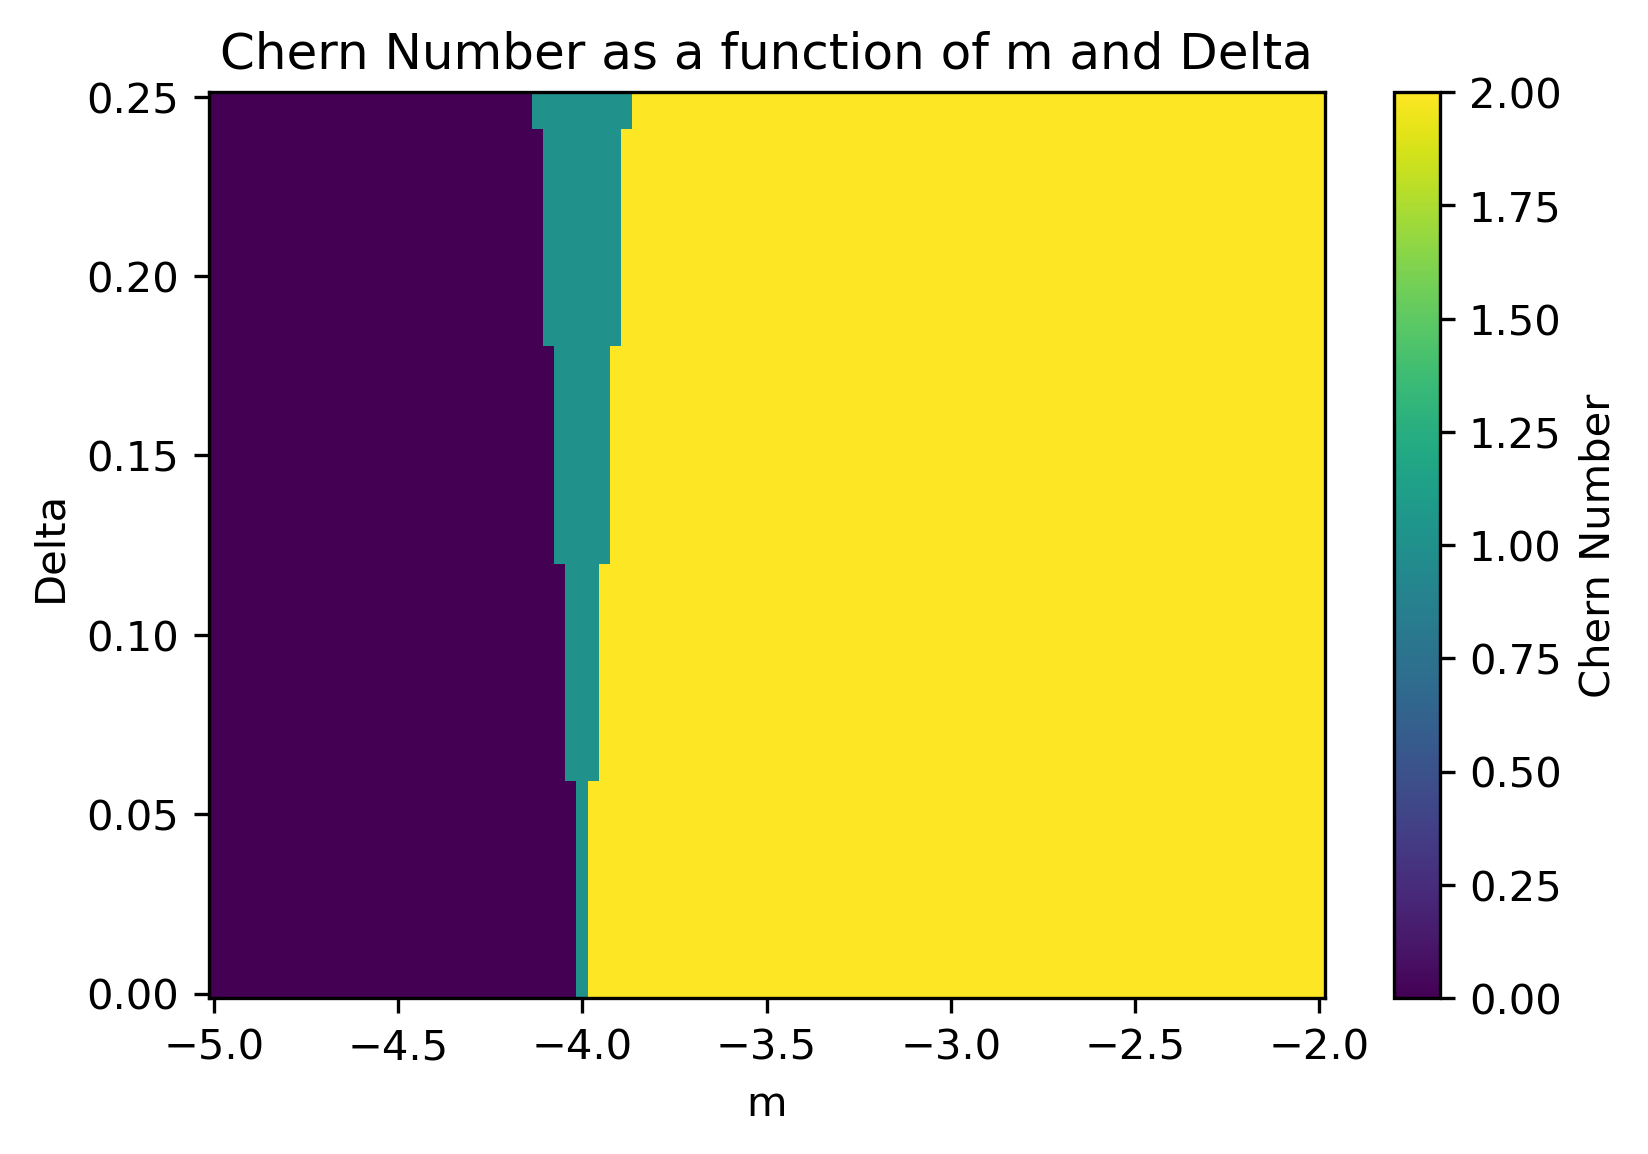

In [5]:
plt.figure(dpi = 300)
plt.pcolormesh(m_values, Delta_values, c_coll.T, shading='auto', cmap='viridis')
plt.colorbar(label='Chern Number')
plt.xlabel('m')
plt.ylabel('Delta')
plt.title('Chern Number as a function of m and Delta')
plt.show()

In [17]:
marker_rules = [
    (c_coll.T < 0.1, "o", "Low"),
    ((c_coll.T >= 0.9) & (c_coll.T < 1.1), "s", "Medium"),
    (c_coll.T >= 1.9, "^", "High")
]

In [18]:
m_mesh, delta_mesh = np.meshgrid(m_values, Delta_values)

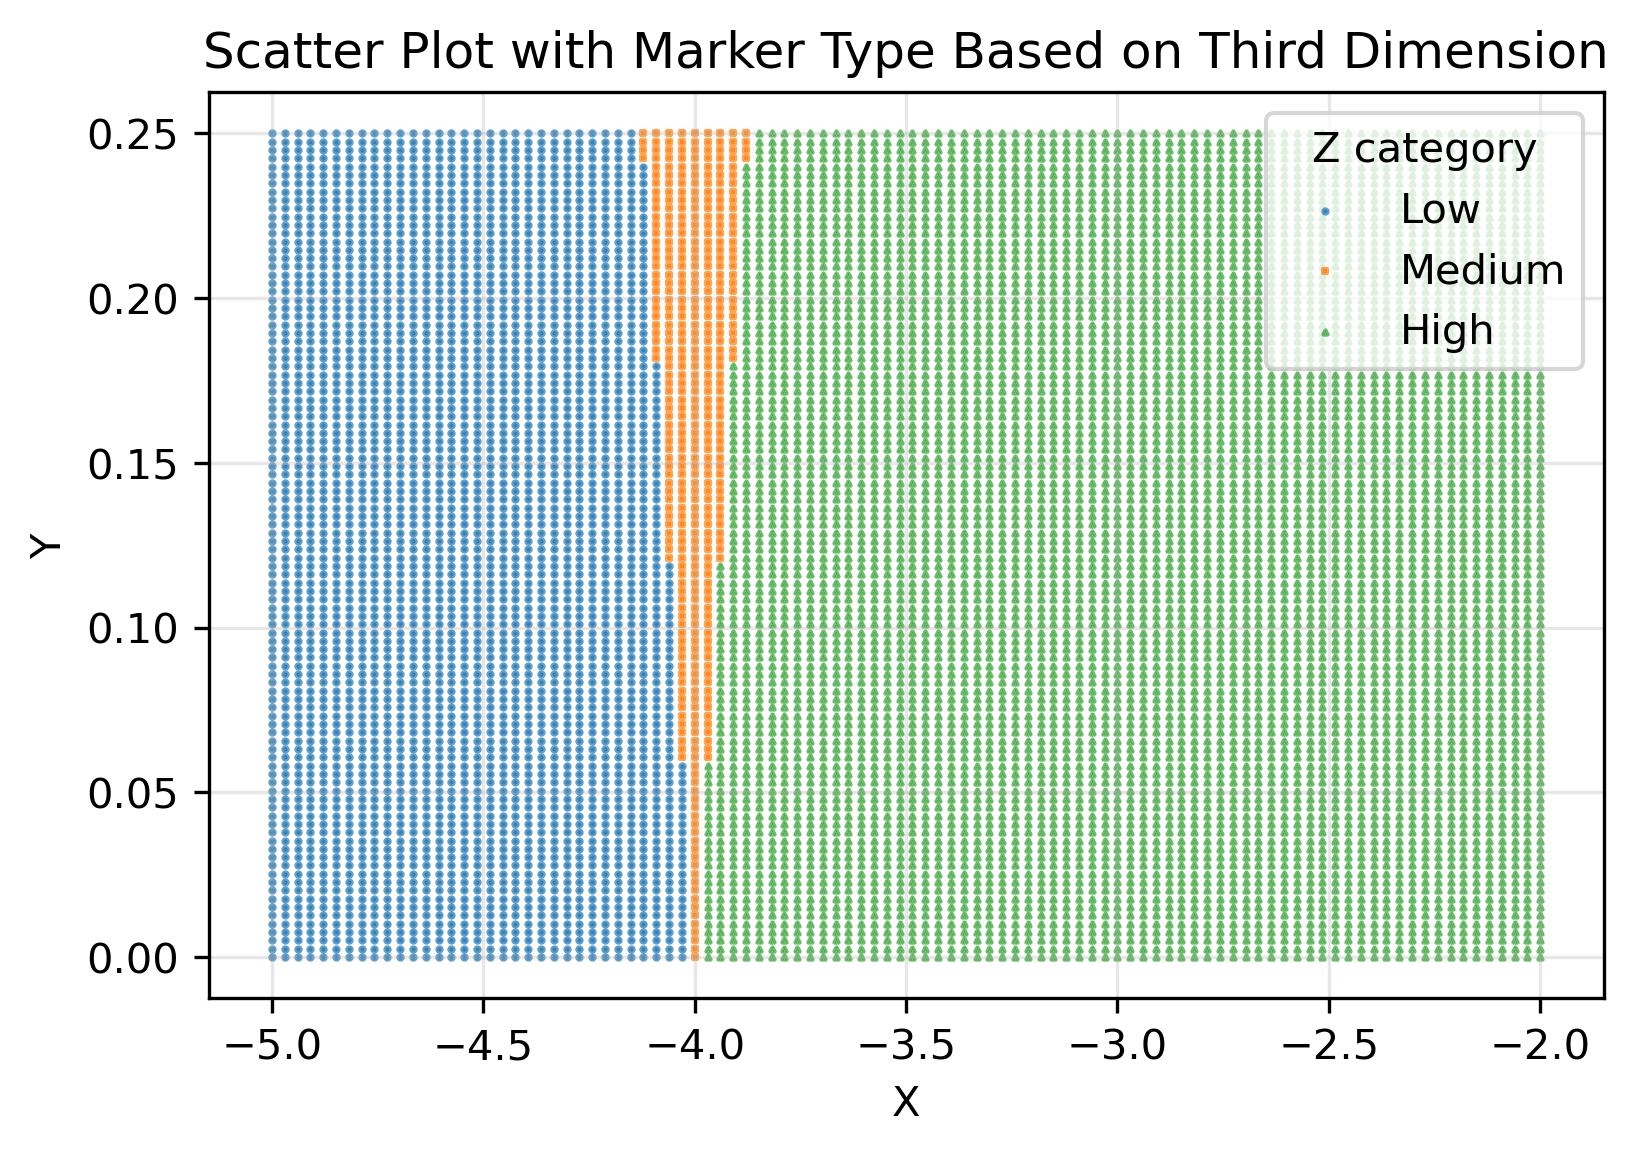

In [22]:
plt.figure(dpi = 300)

# Plot each group with a different marker
for condition, marker, label in marker_rules:
    plt.scatter(
        m_mesh[condition],
        delta_mesh[condition],
        marker=marker,
        label=label,
        s=1,
        alpha=0.7
    )

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Scatter Plot with Marker Type Based on Third Dimension")
plt.legend(title="Z category")
plt.grid(True, alpha=0.3)

plt.show()

In [6]:
BP_coll = np.loadtxt("BerryPhaseData_sweep_test.csv", delimiter = ",")

In [7]:
mu_values_bp = np.linspace(-5, -2, 500)
Delta_values_bp = np.linspace(0, 0.25, 100)

In [8]:
mu_mesh, Delta_mesh = np.meshgrid(mu_values_bp[1::10], Delta_values_bp)

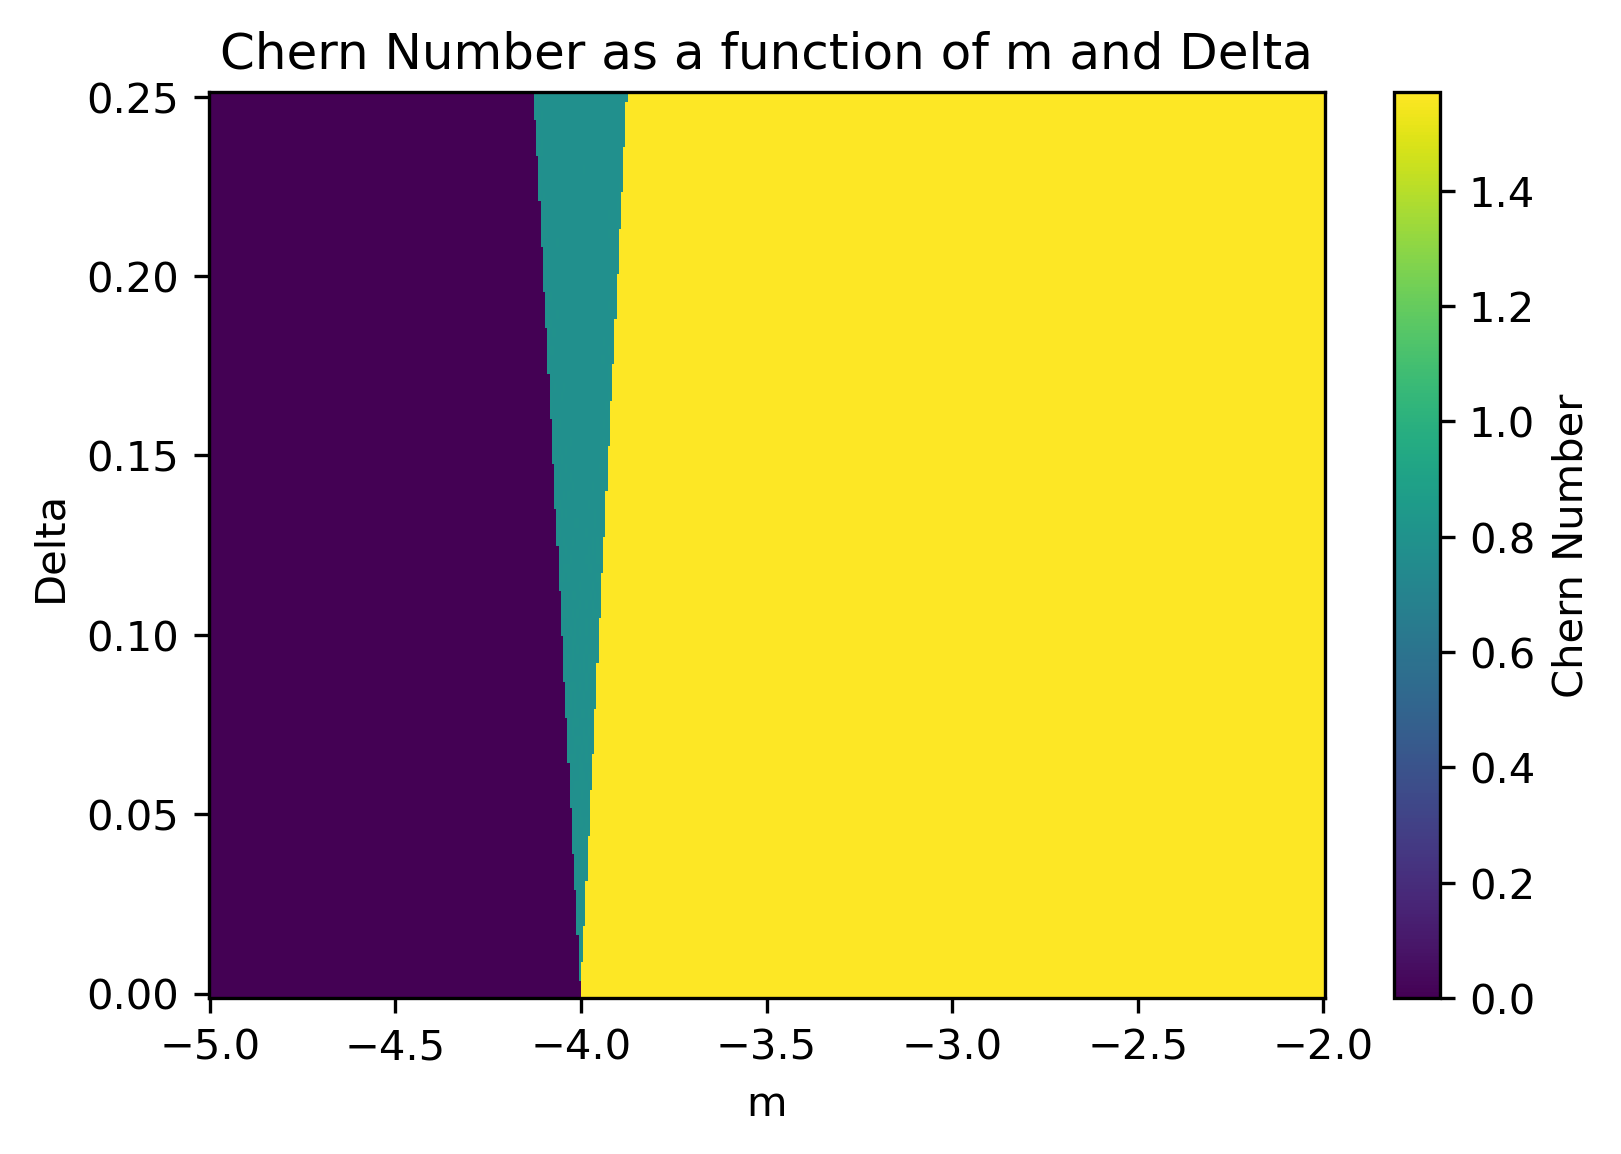

In [9]:
plt.figure(dpi = 300)
plt.pcolormesh(mu_values_bp, Delta_values_bp, BP_coll.T, shading='auto', cmap='viridis')
plt.colorbar(label='Chern Number')
plt.xlabel('m')
plt.ylabel('Delta')
plt.title('Chern Number as a function of m and Delta')
plt.show()

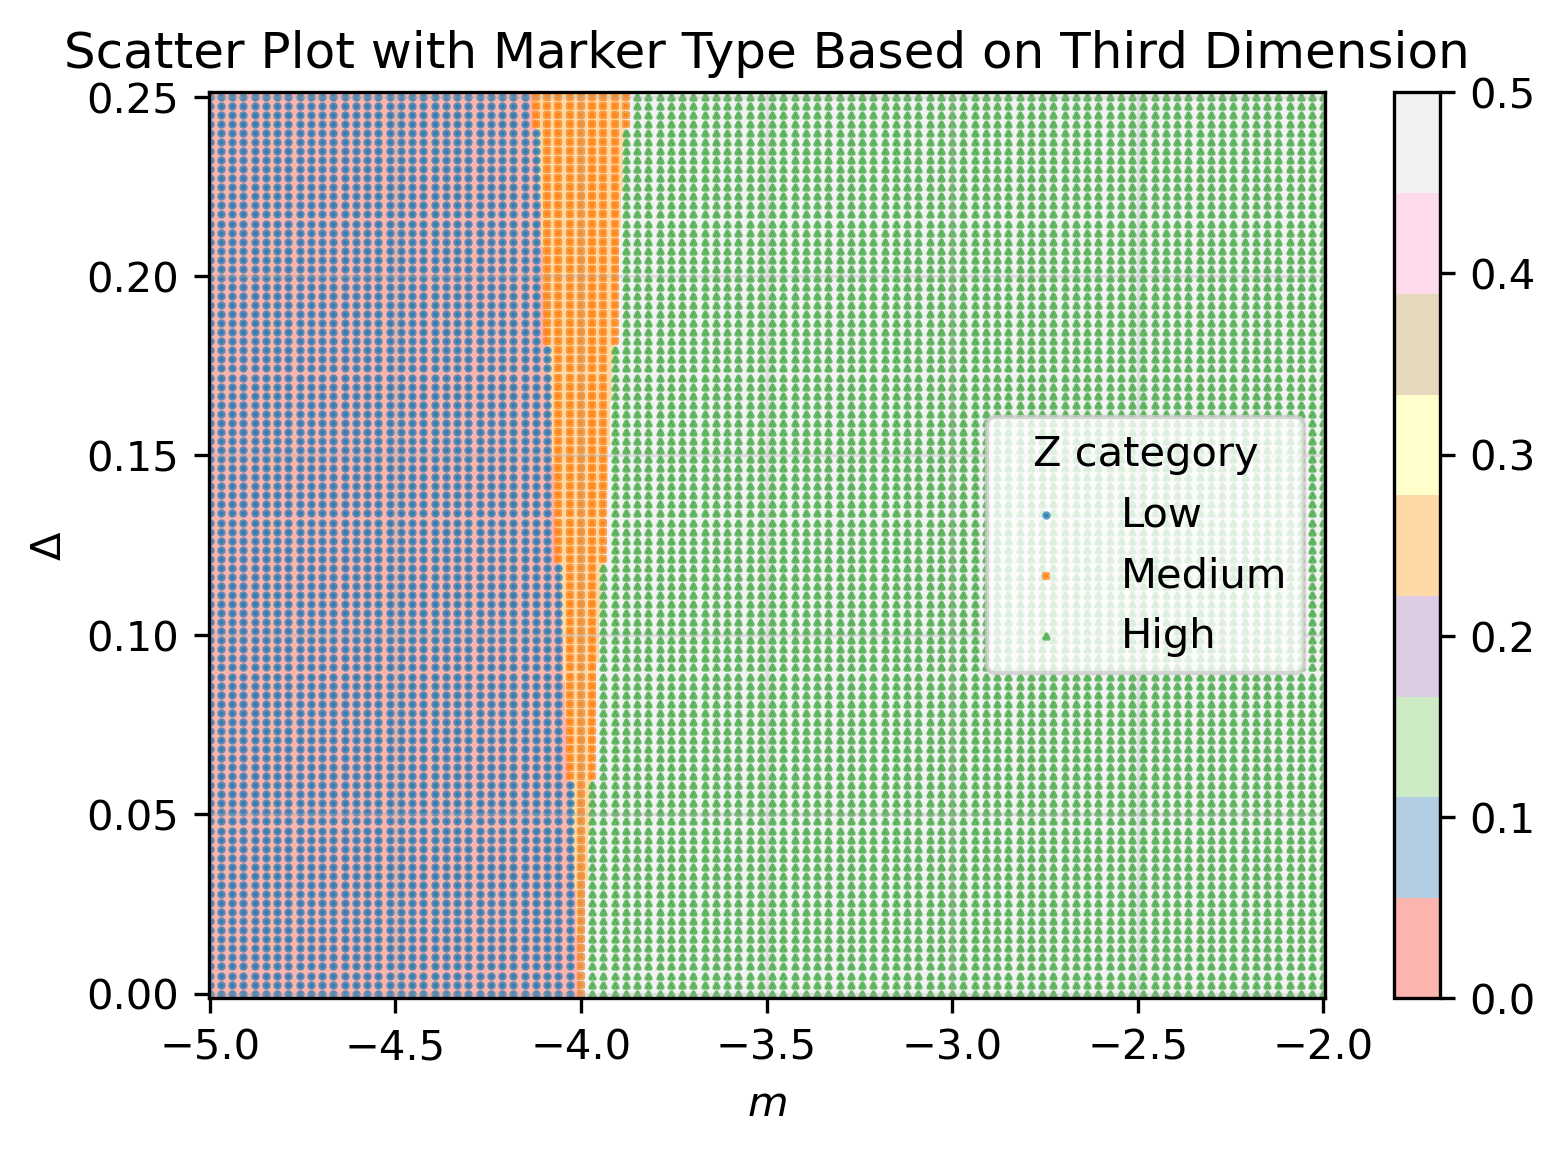

In [28]:
plt.figure(dpi = 300)
plt.pcolormesh(mu_values_bp, Delta_values_bp, BP_coll.T / np.pi, shading='auto', cmap='Pastel1')


# Plot each group with a different marker
for condition, marker, label in marker_rules:
    plt.scatter(
        m_mesh[condition],
        delta_mesh[condition],
        marker=marker,
        label=label,
        s=1,
        alpha=0.7
    )

plt.xlabel(r"$m$")
plt.ylabel(r"$\Delta$")
plt.title("Scatter Plot with Marker Type Based on Third Dimension")
plt.legend(title="Z category")
plt.grid(True, alpha=0.3)

plt.show()